# CE893 project notebook: LoRA vs prompt-engineering harness for a text-to-Cube agent

This notebook reproduces **every number, table and figure in the report** from the evaluation
outputs stored in this repository, and documents where the data comes from.

* Part 1–5 run anywhere in a few seconds (Python only, no GPU, no Cube, no Ollama): they read the
  stored per-question outputs in `results/`.
* Part 6 shows the commands that **produced** those outputs (data preparation, harness runs, LoRA
  training, export). They need BIRD, Node.js (Cube), Ollama and a 16 GB GPU, so they are switched off
  by default (`RUN_PIPELINE = False`).

Run from the repository root or from `notebook/`: `pip install -r requirements.txt pandas matplotlib sqlglot scipy`.

## 1. Data sources

| What | Source | Licence / terms | Where in this repo |
|---|---|---|---|
| Questions, hints, gold SQL, SQLite databases | BIRD benchmark, Li et al., NeurIPS 2023 — https://bird-bench.github.io/ (`dev.zip`, `train.zip`) | CC BY-SA 4.0 | downloaded by `scripts/download_bird.py` (not committed: ~1.5 GB) |
| Test split (332 q: formula_1 174, student_club 158) | BIRD dev | CC BY-SA 4.0 | `splits/test_ids.json` |
| Harness tuning split (superhero, toxicology, california_schools) | BIRD dev | CC BY-SA 4.0 | `splits/tune_ids.json` (120-q subset); all 363 q used for final tuning comparison |
| LoRA training pairs (3,531 verified question → Cube query) | BIRD train, translated by `harness/sql2cube.py`, verified by execution | CC BY-SA 4.0 (derived) | `training_data/verified.jsonl`, schemas in `training_data/schemas/` |
| Synthetic schema questions (noschema arm only) | generated by `scripts/synth_schema_qa.py` from the two test schemas; no BIRD dev question/hint/SQL used | — | regenerate with the script |
| Cube models | generated from BIRD schema + column descriptions by `scripts/gen_cube_models.py` | — | `cube/model/*.yml` |
| Base models | `Qwen/Qwen2.5-Coder-7B-Instruct`, `-14B-Instruct` (Hugging Face); Ollama `qwen2.5-coder:7b/14b` Q4_K_M | Apache 2.0 | downloaded at run time |
| **Evaluation outputs used in the report** | one JSON line per test question per arm: question, gold SQL, predicted Cube query, strict/relaxed correctness, steps, tokens, latency, full tool trace | — | `results/runs/*.jsonl.gz` |
| **Training logs** | Hugging Face Trainer log history + eval loss before training | — | `results/training/*.json` |

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "results").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "report"))
import pandas as pd
import analysis as A
pd.set_option("display.width", 160); pd.set_option("display.max_colwidth", 80)
print("runs:", sorted(p.name for p in A.RUNS.glob("*.jsonl.gz")))
print("training logs:", sorted(p.name for p in A.TRAINING.glob("*.json")))

runs: ['test_harness_14b.jsonl.gz', 'test_harness_7b.jsonl.gz', 'test_harness_v1_7b.jsonl.gz', 'test_harness_v2_7b.jsonl.gz', 'test_lean_14b.jsonl.gz', 'test_lean_7b.jsonl.gz', 'test_lora_14b.jsonl.gz', 'test_lora_7b.jsonl.gz', 'test_lora_on_lean_prompt_14b_partial.jsonl.gz', 'test_lora_on_lean_prompt_7b.jsonl.gz', 'test_nohint_harness_14b.jsonl.gz', 'test_nohint_harness_7b.jsonl.gz', 'test_nohint_lean_14b.jsonl.gz', 'test_nohint_lean_7b.jsonl.gz', 'test_nohint_lora_14b.jsonl.gz', 'test_nohint_lora_7b.jsonl.gz', 'test_nohint_lora_on_lean_prompt_7b.jsonl.gz', 'test_nohint_noschema_14b.jsonl.gz', 'test_nohint_noschema_7b.jsonl.gz', 'test_nohint_noschema_lean_prompt_14b.jsonl.gz', 'test_nohint_noschema_lean_prompt_7b.jsonl.gz', 'test_noschema_14b.jsonl.gz', 'test_noschema_7b.jsonl.gz', 'test_noschema_lean_prompt_14b.jsonl.gz', 'test_noschema_lean_prompt_7b.jsonl.gz', 'tune120_harness_v2_7b.jsonl.gz', 'tune120_harness_v3_7b.jsonl.gz', 'tune120_harness_v4_1_7b.jsonl.gz', 'tune120_harness_v4

In [2]:
# what one stored output record looks like
r = A.test_run("lora_7b").iloc[1]
{k: (v if k != "trace" else f"[{len(v)} trace steps]") for k, v in r.items() if k not in ("has_join", "called_search_values", "n_tool_calls")}

{'question_id': np.int64(847),
 'db_id': 'formula_1',
 'difficulty': 'simple',
 'setup': 'lora-v4.2-7b-nohint',
 'model': 'ollama_chat/qwen7b-cube-lora',
 'mode': 'tools',
 'profile': 'full',
 'question': 'What is the surname of the driver with the best lap time in race number 19 in the second qualifying period?',
 'evidence': 'race number refers to raceId; second qualifying period refers to q2; best lap time refers to MIN(q2);',
 'gold_sql': 'SELECT T2.surname FROM qualifying AS T1 INNER JOIN drivers AS T2 ON T2.driverId = T1.driverId WHERE T1.raceId = 19 ORDER BY T1.q2 ASC LIMIT 1',
 'pred_query': {'dimensions': ['drivers.surname', 'qualifying.q2'],
  'filters': [{'member': 'qualifying.raceId',
    'operator': 'equals',
    'values': ['19']}],
  'limit': 1,
  'order': {'qualifying.q2': 'desc'}},
 'correct': np.False_,
 'correct_relaxed': np.False_,
 'error': nan,
 'steps': np.int64(2),
 'prompt_tokens': np.int64(8595),
 'completion_tokens': np.int64(137),
 'llm_latency_s': np.float64

In [3]:
# the frozen test split and the training data
test_ids = json.loads((ROOT / "splits/test_ids.json").read_text())
train = pd.read_json(ROOT / "training_data/verified.jsonl", lines=True)
print(len(test_ids), "test questions;", len(train), "verified training pairs on", train.db_id.nunique(), "databases;",
      int((train.searches.str.len() > 0).sum()), "with a search_values step")
train[["db_id", "question", "sql", "cube_query"]].head(3)

332 test questions; 3531 verified training pairs on 58 databases; 769 with a search_values step


,db_id,question,sql,cube_query
0,address,What is the total number of households in Arecibo county?,SELECT SUM(T1.households) FROM zip_data AS T1 INNER JOIN country AS T2 ON T1...,"{'measures': ['zip_data.sum_households'], 'filters': [{'member': 'country.co..."
1,address,Which residential area in Arecibo county has the highest average house value...,SELECT T1.zip_code FROM zip_data AS T1 INNER JOIN country AS T2 ON T1.zip_co...,"{'dimensions': ['zip_data.zip_code', 'zip_data.avg_house_value'], 'filters':..."
2,address,Please list the numbers of males in all the residential areas in Arecibo cou...,SELECT SUM(T1.male_population) FROM zip_data AS T1 INNER JOIN country AS T2 ...,"{'measures': ['zip_data.sum_male_population'], 'filters': [{'member': 'count..."


## 2. Main results (Table 5 and Fig. 7)

Every reported test run hides BIRD's hint from the model (`--no-evidence`). Runs with the hint are kept under `hint_*` names for reference (section 2b).

In [4]:
t = A.summary_table()
t[["run", "n", "strict", "relaxed", "prompt_tokens", "steps", "latency_s", "latency_median_s", "latency_p90_s",
   "tokens_per_s", "search_values_pct"]].round(1)

,run,n,strict,relaxed,prompt_tokens,steps,latency_s,latency_median_s,latency_p90_s,tokens_per_s,search_values_pct
key,,,,,,,,,,,
harness_7b,7B harness only,332,21.4,27.7,15929.2,4.1,3.5,2.3,6.8,120.8,92.2
harness_14b,14B harness only,332,27.4,35.8,11952.3,3.2,4.6,3.8,7.0,66.8,48.2
lora_7b,7B LoRA + harness,332,36.7,40.7,7671.6,2.1,1.3,1.2,1.7,104.0,0.9
lora_14b,14B LoRA + harness,332,40.7,45.5,7343.7,2.0,2.4,2.3,3.2,61.3,0.0
lora_on_lean_7b,"7B full LoRA, lean prompt",332,0.0,0.0,5429.1,3.5,3.5,1.6,8.6,114.2,0.0
lean_7b,7B lean LoRA,332,34.6,36.7,3242.4,2.2,1.4,1.2,1.5,109.9,0.3
lean_14b,14B lean LoRA,332,40.1,46.1,2988.3,2.0,2.3,2.2,3.3,65.0,0.0
noschema_7b,"7B no-schema LoRA, no schema",332,18.1,19.9,1616.0,4.5,2.4,1.8,4.5,113.5,0.6
noschema_14b,"14B no-schema LoRA, no schema",332,24.7,25.6,1139.7,2.7,5.6,3.8,13.6,69.7,0.0


In [5]:
pairs = [("harness_7b", "lora_7b"), ("harness_14b", "lora_14b"), ("lora_7b", "lora_14b"), ("harness_7b", "harness_14b"),
         ("harness_7b", "lean_7b"), ("harness_14b", "lean_14b"), ("lora_7b", "lean_7b"), ("lora_14b", "lean_14b"),
         ("lora_14b", "noschema_lean_14b"), ("lora_14b", "noschema_14b")]
pairs = [(a, b) for a, b in pairs if A.available([a, b]) == [a, b]]
pd.DataFrame([A.mcnemar(a, b) for a, b in pairs]).assign(p=lambda d: d.p.map("{:.2g}".format))

,a,b,only_a,only_b,p,n
0,harness_7b,lora_7b,19,70,5e-08,332
1,harness_14b,lora_14b,14,58,1.6e-07,332
2,lora_7b,lora_14b,18,31,0.085,332
3,harness_7b,harness_14b,23,43,0.019,332
4,harness_7b,lean_7b,22,66,2.9e-06,332
5,harness_14b,lean_14b,17,59,1.4e-06,332
6,lora_7b,lean_7b,20,13,0.3,332
7,lora_14b,lean_14b,12,10,0.83,332
8,lora_14b,noschema_lean_14b,12,13,1,332
9,lora_14b,noschema_14b,62,9,7.3e-11,332


In [6]:
rows = []
for run in ["harness_7b", "lora_7b", "harness_14b", "lora_14b"]:
    for by in ["db_id", "has_join", "difficulty"]:
        for k, v in A.breakdown(run, by).items():
            rows.append({"run": run, "group": f"{by}={k}", "strict": round(v, 1)})
pd.DataFrame(rows).pivot(index="group", columns="run", values="strict")

run,harness_14b,harness_7b,lora_14b,lora_7b
group,,,,
db_id=formula_1,19.5,8.6,31.0,28.2
db_id=student_club,36.1,35.4,51.3,46.2
difficulty=challenging,8.7,8.7,4.3,13.0
difficulty=moderate,9.9,15.4,28.6,24.2
difficulty=simple,36.7,25.2,49.5,44.5
has_join=False,43.2,27.0,40.5,43.2
has_join=True,22.9,19.8,40.7,34.9


## 2b. Tool use (Table 6), and the same arms with BIRD's hint (for reference)

In [7]:
A.tool_table(A.MAIN_ARMS).round(2)

,run,search_values_per_q,run_query_per_q,submit_per_q,rejected_per_q,text_calls_pct,no_answer_pct,empty_answer_pct
harness_7b,7B harness only,1.97,0.69,1.00,1.09,15.99,5.42,2.41
lora_7b,7B LoRA + harness,0.01,1.09,1.03,0.11,0.14,0.00,12.95
harness_14b,14B harness only,0.95,0.95,0.93,0.14,53.67,0.90,10.24
lora_14b,14B LoRA + harness,0.00,0.97,0.99,0.00,100.00,0.00,13.25


In [8]:
hint = ["hint_" + k for k in A.MAIN_ARMS]
pd.concat([A.summary_table(A.MAIN_ARMS), A.summary_table(hint)])[["run", "strict", "relaxed", "steps", "latency_s"]].round(1)

,run,strict,relaxed,steps,latency_s
key,,,,,
harness_7b,7B harness only,21.4,27.7,4.1,3.5
lora_7b,7B LoRA + harness,36.7,40.7,2.1,1.3
harness_14b,14B harness only,27.4,35.8,3.2,4.6
lora_14b,14B LoRA + harness,40.7,45.5,2.0,2.4
hint_harness_7b,7B harness only (hint),27.7,34.0,4.0,3.2
hint_lora_7b,7B LoRA + harness (hint),46.4,52.1,2.1,1.3
hint_harness_14b,14B harness only (hint),28.9,41.3,2.9,4.0
hint_lora_14b,14B LoRA + harness (hint),49.7,56.9,2.0,2.5


In [9]:
pd.DataFrame([A.mcnemar("hint_" + k, k) for k in A.MAIN_ARMS]).assign(p=lambda d: d.p.map("{:.2g}".format))

,a,b,only_a,only_b,p,n
0,hint_harness_7b,harness_7b,41,20,0.0099,332
1,hint_lora_7b,lora_7b,38,6,9.4e-07,332
2,hint_harness_14b,harness_14b,29,24,0.58,332
3,hint_lora_14b,lora_14b,35,5,1.4e-06,332


## 3. Prompt versions and training progress (Fig. 4 and Fig. 6)

In [10]:
pd.DataFrame({**{f"test {k}": A.summary(A.test_run(k)) for k in ["hint_harness_v1_7b", "hint_harness_v2_7b", "hint_harness_7b"]},
              **{f"tune120 {k}": A.summary(A.load_run(v)) for k, v in A.TUNE_RUNS.items()},
              **{f"tune363 {k}": A.summary(A.load_run(v)) for k, v in A.TUNE363_RUNS.items()}}).T[["n", "strict", "relaxed", "prompt_tokens", "steps"]].round(1)

,n,strict,relaxed,prompt_tokens,steps
test hint_harness_v1_7b,332.0,13.3,26.8,12300.0,3.6
test hint_harness_v2_7b,332.0,20.5,34.3,13504.2,3.5
test hint_harness_7b,332.0,27.7,34.0,15741.6,4.0
tune120 v2,120.0,22.5,28.3,12491.6,3.3
tune120 v3,120.0,23.3,27.5,12322.7,3.4
tune120 v4,120.0,22.5,29.2,13751.7,3.6
tune120 v4.1,120.0,24.2,30.8,13244.8,3.6
tune363 v3 7B,363.0,26.2,33.6,10828.1,3.4
tune363 v4.2 7B,363.0,32.0,35.3,12225.9,3.8
tune363 v4.2 14B,363.0,38.8,47.9,8664.5,2.7


In [11]:
pd.DataFrame([{**{k: A.training_log(n)["config"][k] for k in ["base", "max_len", "train_examples", "val_examples"]},
               "run": n, "hours": round(A.training_log(n)["runtime_h"], 2),
               "val_loss": [round(x, 3) for x in A.training_log(n)["eval"]["eval_loss"]]} for n in A.TRAIN_LOGS]).set_index("run")

,base,max_len,train_examples,val_examples,hours,val_loss
run,,,,,,
lora_full_7b,Qwen/Qwen2.5-Coder-7B-Instruct,8192,2929,258,5.34,"[1.0, 0.275, 0.274, 0.274, 0.274]"
lora_full_14b,Qwen/Qwen2.5-Coder-14B-Instruct,4096,2621,139,8.96,"[0.786, 0.273, 0.271, 0.271, 0.271]"
lora_lean_7b,Qwen/Qwen2.5-Coder-7B-Instruct,8192,2929,258,2.01,"[1.465, 0.276, 0.273, 0.274, 0.274]"
lora_lean_14b,Qwen/Qwen2.5-Coder-14B-Instruct,4096,2621,139,2.92,"[1.06, 0.275, 0.272, 0.272, 0.272]"
lora_noschema_7b,Qwen/Qwen2.5-Coder-7B-Instruct,8192,4164,323,2.47,"[1.495, 0.286, 0.282, 0.281, 0.281]"
lora_noschema_14b,Qwen/Qwen2.5-Coder-14B-Instruct,4096,3856,204,3.66,"[1.146, 0.288, 0.285, 0.285, 0.284]"


## 4. Errors and real outputs (Fig. 9 and Fig. 10)

Each wrong answer gets one rule-based category (`analysis.error_category`, rules applied in order). The rules compare the predicted Cube query with the gold SQL; they describe where the query differs, not why the model erred.

In [12]:
pd.DataFrame({r: A.error_counts(r) for r in A.available(["harness_7b", "lora_7b", "harness_14b", "lora_14b", "lean_14b", "noschema_14b"])})

,harness_7b,lora_7b,harness_14b,lora_14b,lean_14b,noschema_14b
No valid answer (error / call limit),45,4,20,4,2,66
Needs SQL Cube cannot express,56,56,59,55,57,50
Extra columns only,21,13,28,16,20,3
Wrong filter value,64,50,48,39,42,39
Aggregation missing or wrong,8,5,8,5,6,5
Wrong columns returned,16,21,29,23,22,22
Ranking / limit missing,4,1,1,1,2,6
Wrong field or join path,47,60,48,54,48,59


In [13]:
h, l = A.test_run("harness_7b"), A.test_run("lora_7b")
for qid in [923, 1314]:
    print(f"Q{qid}: {h.loc[qid, 'question']}\nGOLD: {h.loc[qid, 'gold_sql']}")
    for name, df in [("harness only", h), ("LoRA", l)]:
        print(f"--- 7B {name}: {'correct' if df.loc[qid, 'correct'] else 'wrong'} ({A.error_category(df.loc[qid])})")
        print(A.render_trace(df.loc[qid], 160))
    print()

Q923: How many Formula_1 races took place on the circuits in Italy?
GOLD: SELECT COUNT(T2.circuitId) FROM circuits AS T1 INNER JOIN races AS T2 ON T2.circuitID = T1.circuitId WHERE T1.country = 'Italy'
--- 7B harness only: wrong (Wrong columns returned)
> search_values({"dimension":"circuits.country","text":"Italy"})
  < ["Italy"]
> run_query({"measures":["races.count"],"dimensions":["races.circuitId"],"filters":[{"member":"circuits.country","operator":"equals","values":["Italy"]}]})
  < {"row_count": 3, "rows": [{"races.circuitId": "14", "races.count": "67"}, {"races.circuitId": "21", "races.count": "27"}, {"races.circuitId": "65", "races.count ...
> submit_answer({"dimensions":["races.circuitId"],"filters":[{"member":"circuits.country","operator":"equals","values":["Italy"]}],"measures":["races.count"]})
  < Accepted.
--- 7B LoRA: correct (None)
> run_query({"measures":["races.count"],"filters":[{"member":"circuits.country","operator":"equals","values":["Italy"]}]})
  < {"row_count":

In [14]:
# a random sample of LoRA errors, so the report does not show only chosen cases
wrong = l[~l.correct].sample(5, random_state=0)
for qid, row in wrong.iterrows():
    print(f"Q{qid} [{A.error_category(row)}] {row.question}\n  pred: {json.dumps(row.pred_query)[:200]}\n  gold: {row.gold_sql[:200]}\n")

Q865 [Wrong columns returned] For all the drivers who finished the game in race No. 592, who is the oldest?
  pred: {"dimensions": ["drivers.forename", "drivers.surname", "drivers.dob"], "filters": [{"member": "results.raceId", "operator": "equals", "values": ["592"]}], "limit": 1, "order": {"drivers.dob": "asc"}}
  gold: SELECT T1.forename, T1.surname FROM drivers AS T1 INNER JOIN results AS T2 ON T2.driverId = T1.driverId WHERE T2.raceId = 592 AND T2.time IS NOT NULL AND T1.dob IS NOT NULL ORDER BY T1.dob ASC LIMIT 1

Q960 [Wrong field or join path] What is the average of fastest lap speed in the 2009 Spanish Grand Prix race?
  pred: {"filters": [{"member": "races.year", "operator": "equals", "values": ["2009"]}, {"member": "circuits.name", "operator": "equals", "values": ["Spanish Grand Prix"]}], "measures": ["results.avg_fastest
  gold: SELECT AVG(T1.fastestLapSpeed) FROM results AS T1 INNER JOIN races AS T2 on T1.raceId = T2.raceId WHERE T2.year = 2009 AND T2.name = 'Spanish Grand

## 5. Regenerate all report figures

drew fig_glance
drew fig_pipeline
drew fig_data
drew fig_harness_versions
drew fig_method
drew fig_training
drew fig_main
drew fig_offload
drew fig_outputs
drew fig_errors



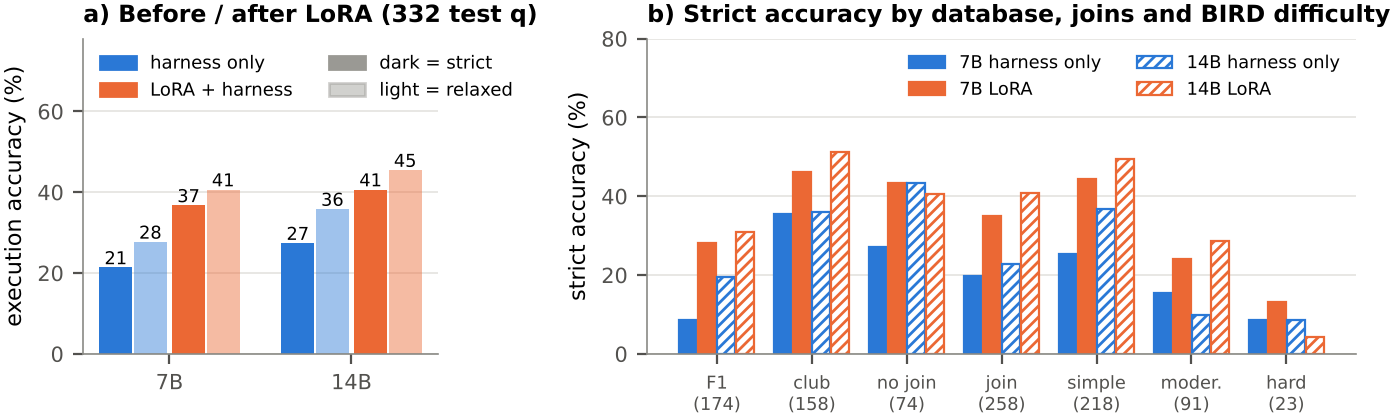

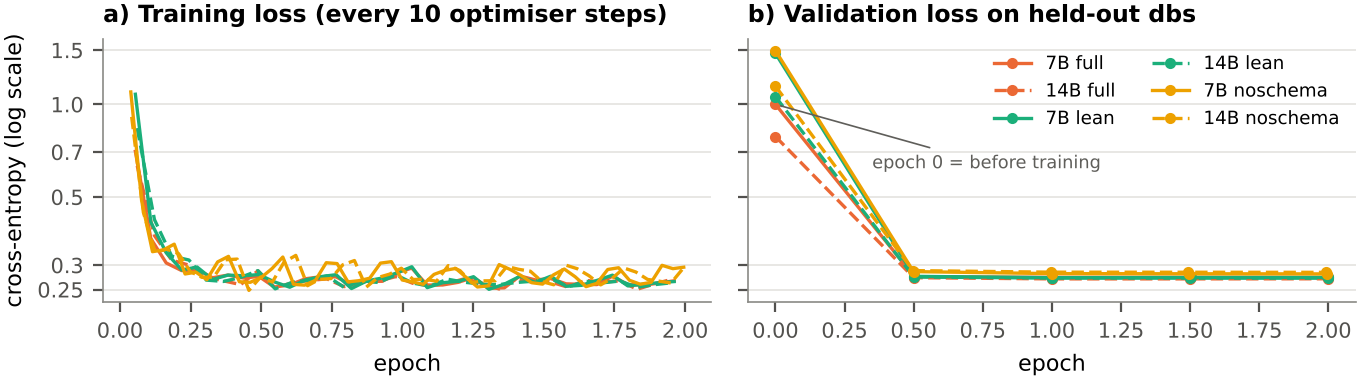

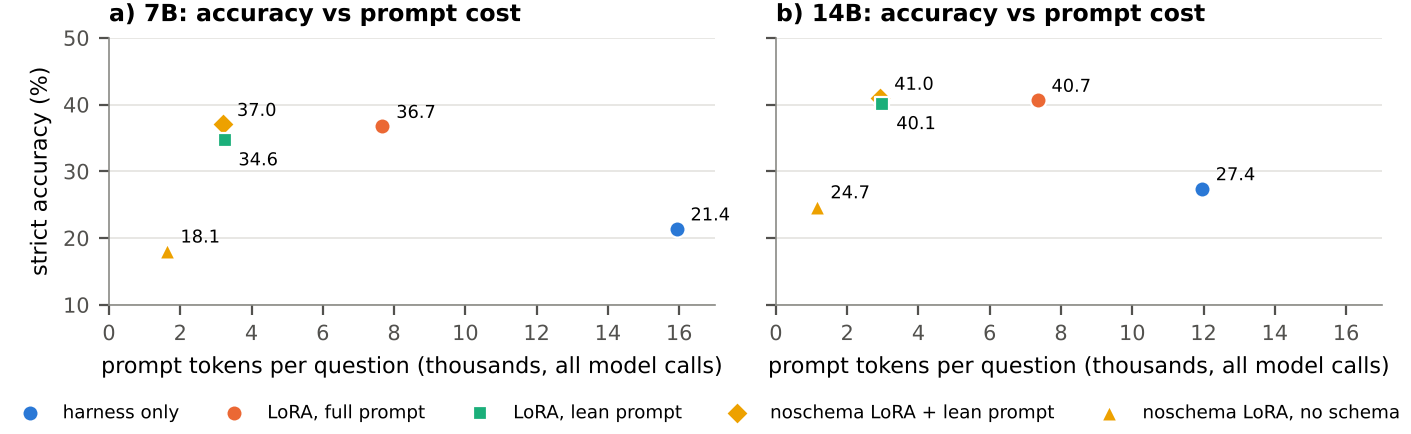

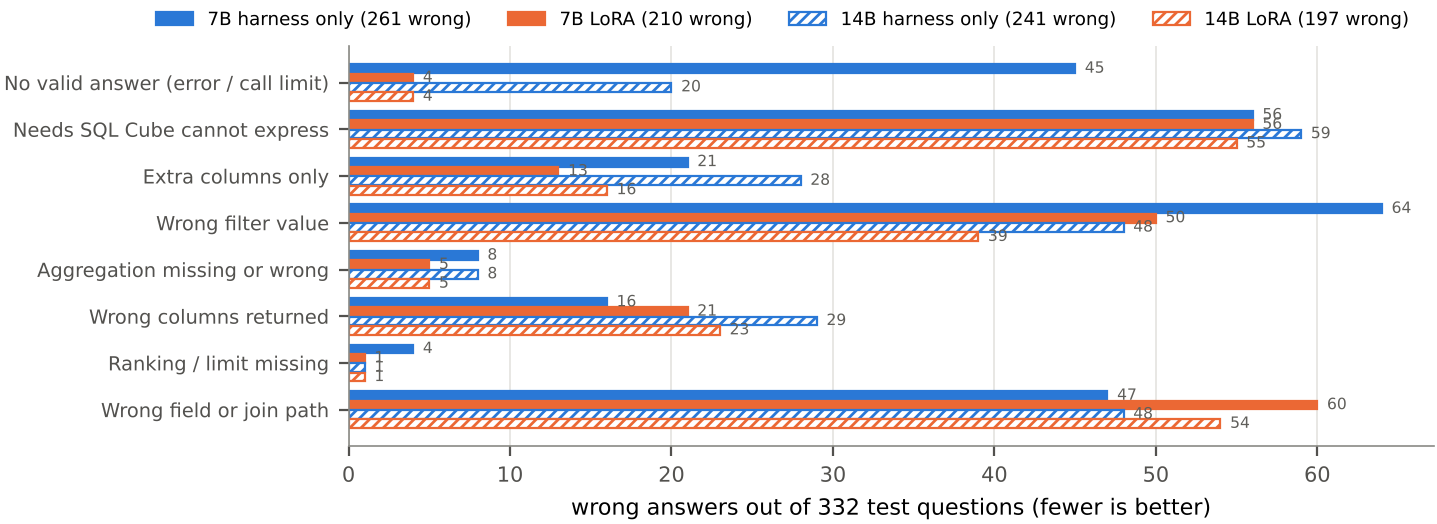

In [15]:
import subprocess
print(subprocess.run([sys.executable, str(ROOT / "report/make_figures.py")], cwd=ROOT / "report", capture_output=True, text=True).stdout)
from IPython.display import Image, display
for f in ["fig07_main", "fig06_training", "fig08_offload", "fig10_errors"]:
    display(Image(filename=str(ROOT / f"report/figures/{f}.png"), width=760))

## 6. How the stored outputs were produced (optional, long-running)

These cells document the full pipeline. Set `RUN_PIPELINE = True` only on a machine with BIRD downloaded,
Cube running on :4000 (`cd cube && npm install && npm run dev`), Ollama, and a 16 GB GPU for training.
Runtimes on an RTX 5070 Ti: one 332-question eval ≈ 10–25 min; 7B LoRA ≈ 5.3 h, 14B ≈ 9 h.

In [16]:
RUN_PIPELINE = False
STEPS = [
    # data
    "python scripts/download_bird.py",
    "python scripts/build_duckdb.py --bird-dir data/bird --out data/bird.duckdb --db formula_1 --db student_club --db superhero --db toxicology --db california_schools",
    "python scripts/gen_cube_models.py --bird-dir data/bird --out cube/model --db formula_1 --db student_club --db superhero --db toxicology --db california_schools",
    "python scripts/build_training_data.py --bird-dir data/bird_train --out data/training   # needs train.zip; already in training_data/",
    "python scripts/make_sft.py --data training_data --out data/sft",
    # baseline arms
    "python -m harness.evaluate --db formula_1 --db student_club --ids-file splits/test_ids.json --no-evidence --model ollama_chat/qwen2.5-coder:7b --setup harness-v4.2-7b-nohint --out runs/test_nohint_harness_7b.jsonl",
    "python -m harness.evaluate --db formula_1 --db student_club --ids-file splits/test_ids.json --no-evidence --model ollama_chat/qwen2.5-coder:14b --setup harness-v4.2-14b-nohint --out runs/test_nohint_harness_14b.jsonl",
    # LoRA arm (7B; same with 14B and --max-len 4096)
    "python scripts/train_lora.py --base Qwen/Qwen2.5-Coder-7B-Instruct --out lora/qwen7b",
    "python scripts/export_ollama.py --base Qwen/Qwen2.5-Coder-7B-Instruct --adapter lora/qwen7b/final --llama-cpp ../llama.cpp --quantize ../llama.cpp/build/bin/llama-quantize --ollama-base qwen2.5-coder:7b --name qwen7b-cube-lora",
    "python -m harness.evaluate --db formula_1 --db student_club --ids-file splits/test_ids.json --no-evidence --model ollama_chat/qwen7b-cube-lora --setup lora-v4.2-7b-nohint --out runs/test_nohint_lora_7b.jsonl",
    # prompt-offloading arms
    "python scripts/make_sft.py --data training_data --profile lean --out data/sft_lean",
    "python scripts/synth_schema_qa.py --db formula_1 --n 800 --db student_club --n 500 --out data/synth/synth.jsonl --audit",
    "python scripts/make_sft.py --data training_data --profile noschema --synthetic data/synth/synth.jsonl --out data/sft_noschema",
    "python -m harness.evaluate --db formula_1 --db student_club --ids-file splits/test_ids.json --no-evidence --profile lean --model ollama_chat/qwen7b-cube-lean --setup lora-lean-7b-nohint --out runs/test_nohint_lean_7b.jsonl",
]
for s in STEPS:
    print("$", s)
    if RUN_PIPELINE:
        subprocess.run(s.split("#")[0], shell=True, cwd=ROOT, check=True)

$ python scripts/download_bird.py
$ python scripts/build_duckdb.py --bird-dir data/bird --out data/bird.duckdb --db formula_1 --db student_club --db superhero --db toxicology --db california_schools
$ python scripts/gen_cube_models.py --bird-dir data/bird --out cube/model --db formula_1 --db student_club --db superhero --db toxicology --db california_schools
$ python scripts/build_training_data.py --bird-dir data/bird_train --out data/training   # needs train.zip; already in training_data/
$ python scripts/make_sft.py --data training_data --out data/sft
$ python -m harness.evaluate --db formula_1 --db student_club --ids-file splits/test_ids.json --no-evidence --model ollama_chat/qwen2.5-coder:7b --setup harness-v4.2-7b-nohint --out runs/test_nohint_harness_7b.jsonl
$ python -m harness.evaluate --db formula_1 --db student_club --ids-file splits/test_ids.json --no-evidence --model ollama_chat/qwen2.5-coder:14b --setup harness-v4.2-14b-nohint --out runs/test_nohint_harness_14b.jsonl
$ pyt

After a new run, gzip the output into `results/runs/` under the file name used in `report/analysis.py` and re-run this notebook.